In [3]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from torchdiffeq import odeint, odeint_adjoint

device = "cuda" if torch.cuda.is_available() else "cpu"

In [4]:
class Cos(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, t, z):
        x, y = z[..., 0], z[..., 1]
        dx = -2*(torch.cos(x) - torch.sin(x)) - (torch.cos(y) - torch.sin(y))
        dy = -2*(torch.cos(y) - torch.sin(y)) - (torch.cos(x) - torch.sin(x))
        return torch.stack([dx, dy], dim=-1)

In [5]:
class ODEmodel(nn.Module):
    def __init__(self, state_dim=2, hidden=64, time_dependent=True):
        super().__init__()
        self.time_dependent = time_dependent

        in_dim = state_dim + (1 if time_dependent else 0)
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden), nn.Softplus(),
            nn.Linear(hidden, hidden), nn.Softplus(),
            nn.Linear(hidden, state_dim),
        )

    def forward(self, t, z):
        if z.dim() == 1:
            z = z.unsqueeze(0)
        if self.time_dependent:
            t_col = torch.full((z.size(0), 1), float(t), device=z.device, dtype=z.dtype)
            h = torch.cat([z, t_col], dim=-1)
        else:
            h = z
        return self.net(h)


class NeuralODE(nn.Module):
    def __init__(self, func, use_adjoint=True, rtol=1e-3, atol=1e-4, method="dopri5"):
        super().__init__()
        self.func = func
        self.use_adjoint = use_adjoint
        self.rtol = rtol
        self.atol = atol
        self.method = method

    def forward(self, z0, t):
        solver = odeint_adjoint if self.use_adjoint else odeint
        Z = solver(self.func, z0, t, rtol=self.rtol, atol=self.atol, method=self.method)
        return Z.transpose(0, 1).contiguous()

In [6]:
ckpt = torch.load("model.pt", map_location=device)

func = ODEmodel(
    state_dim=2,
    hidden=ckpt["hidden"],
    time_dependent=ckpt["time_dependent"]
).to(device)

node = NeuralODE(
    func,
    use_adjoint=ckpt["use_adjoint"]
).to(device)

node.load_state_dict(ckpt["model_state"])
node.eval()

true_func = Cos().to(device)

In [7]:
equilibria = torch.load("equilibria.pt", map_location=device)
print("Loaded equilibria:", len(equilibria))
for i, p in enumerate(equilibria, 1):
    print(i, p.detach().cpu().numpy())

Loaded equilibria: 4
1 [0.7785265  0.77410215]
2 [-2.4117532  0.8121769]
3 [-2.3715618 -2.466326 ]
4 [ 0.68453985 -2.5792139 ]


In [8]:
dataset = torch.load("dataset.pt", map_location=device)

z0_all = dataset["z0_all"].to(device)
t_eval = dataset["t_eval"].to(device)
Z_all = dataset["Z_all"].to(device)

print(z0_all.shape, t_eval.shape, Z_all.shape)

torch.Size([400, 2]) torch.Size([100]) torch.Size([400, 100, 2])


In [9]:
def predict_traj(model, z0, t_eval):
    with torch.no_grad():
        pred = model(z0, t_eval)
    return pred

In [17]:
def plot_time_series(true_Z, pred_Z, t_eval, idx=0):
    t = t_eval.detach().cpu().numpy()
    true_np = true_Z[idx].detach().cpu().numpy()
    pred_np = pred_Z[idx].detach().cpu().numpy()

    plt.figure(figsize=(10, 4))
    plt.plot(t, true_np[:, 0], label="x true")
    plt.plot(t, pred_np[:, 0], "--", label="x pred")
    plt.plot(t, true_np[:, 1], label="y true")
    plt.plot(t, pred_np[:, 1], "--", label="y pred")
    plt.xlabel("t")
    plt.ylabel("state")
    plt.title(f"Time series comparison (sample {idx})")
    plt.grid(True)
    plt.legend()
    plt.show()

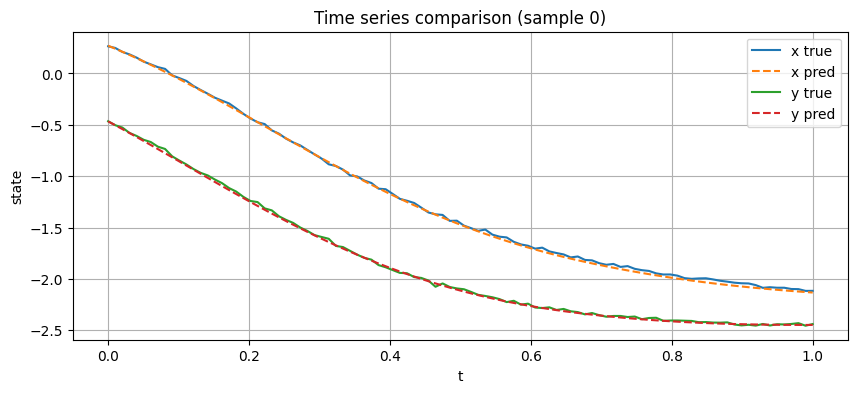

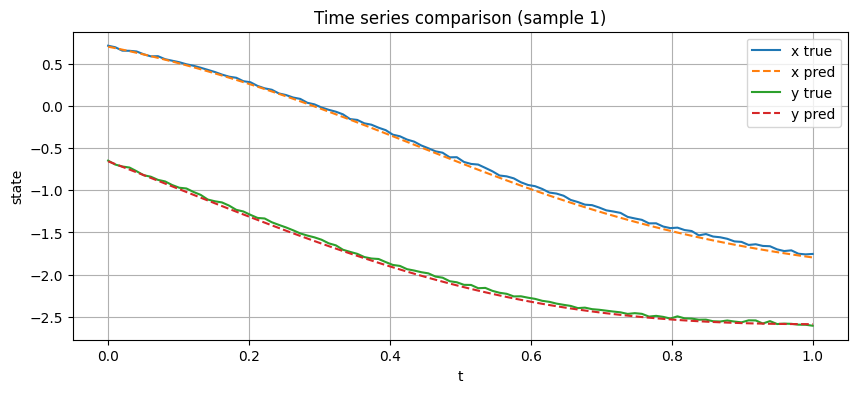

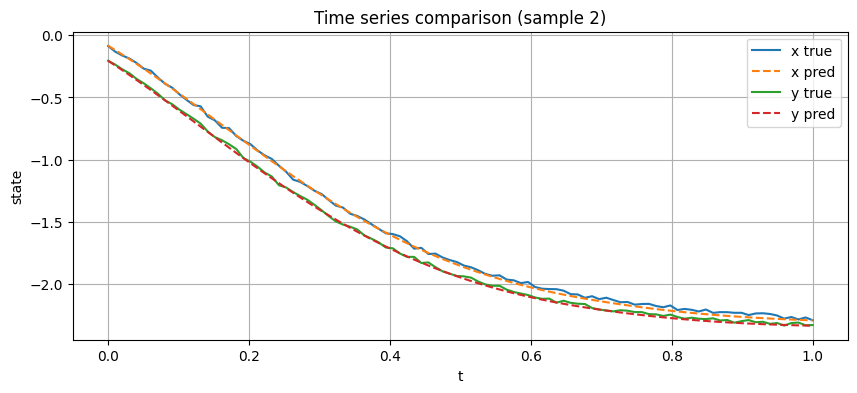

In [18]:
Z_pred_all = predict_traj(node, z0_all, t_eval)
plot_time_series(Z_all, Z_pred_all, t_eval, idx=0)
plot_time_series(Z_all, Z_pred_all, t_eval, idx=1)
plot_time_series(Z_all, Z_pred_all, t_eval, idx=2)

In [21]:
def plot_phase_comparison(true_Z, pred_Z, n_samples=20):
    plt.figure(figsize=(7, 7))

    n = min(n_samples, true_Z.size(0))

    for i in range(n):
        true_np = true_Z[i].detach().cpu().numpy()
        pred_np = pred_Z[i].detach().cpu().numpy()

        if i == 0:
            plt.plot(true_np[:, 0], true_np[:, 1], label="True trajectory", alpha=0.7)
            plt.plot(pred_np[:, 0], pred_np[:, 1], "--", label="Neural ODE", alpha=0.7)
            plt.scatter(true_np[0, 0], true_np[0, 1], s=20, label="Initial state")
        else:
            plt.plot(true_np[:, 0], true_np[:, 1], alpha=0.7)
            plt.plot(pred_np[:, 0], pred_np[:, 1], "--", alpha=0.7)
            plt.scatter(true_np[0, 0], true_np[0, 1], s=20)

    plt.xlabel("x")
    plt.ylabel("y")
    plt.title("Phase portrait: true vs Neural ODE")
    plt.grid(True)
    plt.legend()
    plt.show()

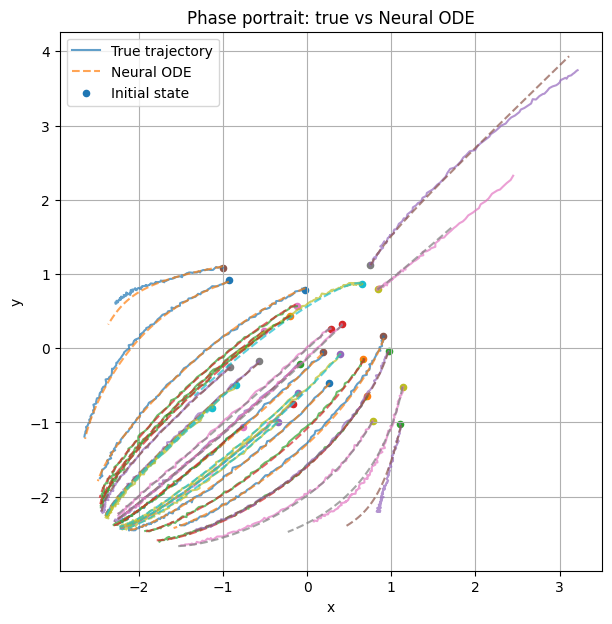

In [22]:
plot_phase_comparison(Z_all, Z_pred_all, n_samples=30)

In [21]:
def plot_vector_field_comparison(true_func, learned_func, xlim=(-1.5, 1.5), ylim=(-1.5, 1.5), n=20):
    x = np.linspace(xlim[0], xlim[1], n)
    y = np.linspace(ylim[0], ylim[1], n)
    X, Y = np.meshgrid(x, y)

    U_true = np.zeros_like(X)
    V_true = np.zeros_like(Y)
    U_pred = np.zeros_like(X)
    V_pred = np.zeros_like(Y)

    t0 = torch.tensor(0.0, device=device)

    for i in range(n):
        for j in range(n):
            z = torch.tensor([[X[i, j], Y[i, j]]], dtype=torch.float32, device=device)

            with torch.no_grad():
                vt = true_func(t0, z).squeeze(0).cpu().numpy()
                vp = learned_func(t0, z).squeeze(0).cpu().numpy()

            U_true[i, j], V_true[i, j] = vt[0], vt[1]
            U_pred[i, j], V_pred[i, j] = vp[0], vp[1]

    plt.figure(figsize=(14, 6))

    plt.subplot(1, 2, 1)
    plt.quiver(X, Y, U_true, V_true)
    plt.title("True vector field")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.grid(True)

    plt.subplot(1, 2, 2)
    plt.quiver(X, Y, U_pred, V_pred)
    plt.title("Learned vector field")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.grid(True)

    plt.tight_layout()
    plt.show()

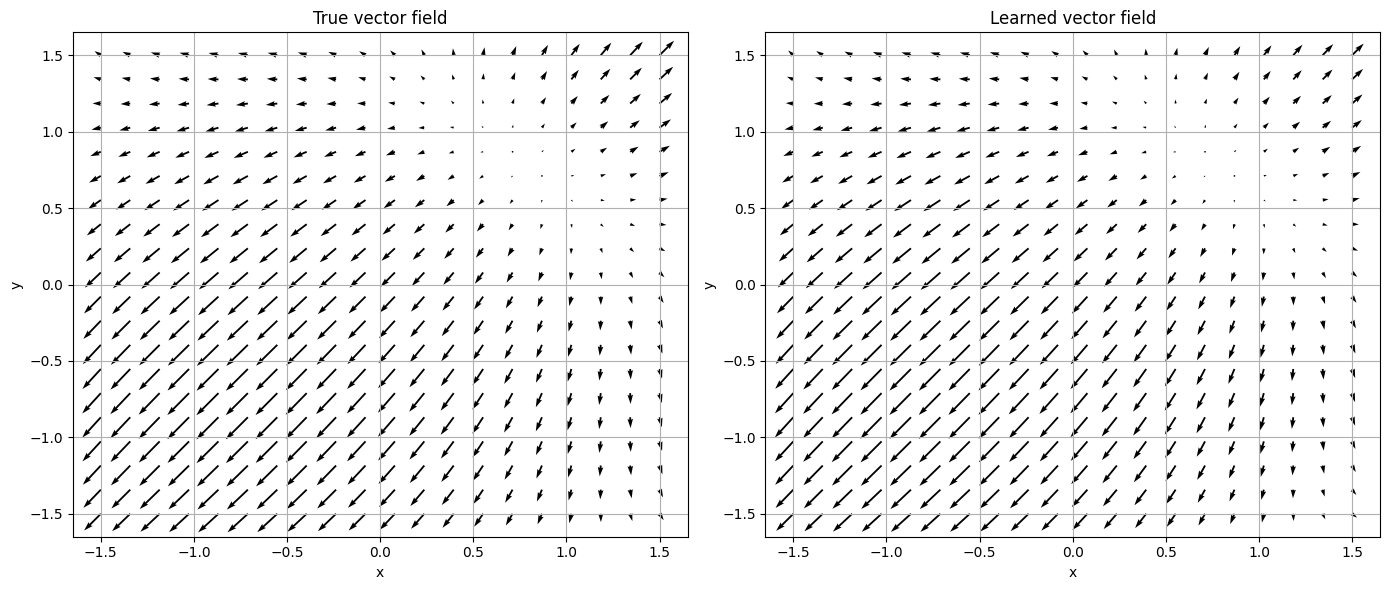

In [22]:
plot_vector_field_comparison(true_func, node.func)

In [ ]:
def plot_vector_field_overlay(true_func, learned_func,
                              xlim=(-1.5, 1.5), ylim=(-1.5, 1.5),
                              n=20, y_shift=0.06):
    x = np.linspace(xlim[0], xlim[1], n)
    y = np.linspace(ylim[0], ylim[1], n)
    X, Y = np.meshgrid(x, y)

    U_true = np.zeros_like(X)
    V_true = np.zeros_like(Y)
    U_pred = np.zeros_like(X)
    V_pred = np.zeros_like(Y)

    t0 = torch.tensor(0.0, device=device)

    for i in range(n):
        for j in range(n):
            z = torch.tensor([[X[i, j], Y[i, j]]], dtype=torch.float32, device=device)

            with torch.no_grad():
                vt = true_func(t0, z).squeeze(0).cpu().numpy()
                vp = learned_func(t0, z).squeeze(0).cpu().numpy()

            U_true[i, j], V_true[i, j] = vt[0], vt[1]
            U_pred[i, j], V_pred[i, j] = vp[0], vp[1]

    plt.figure(figsize=(10, 8))

    
    plt.quiver(X, Y, U_true, V_true, color='black', alpha=0.85, label='True system')

    plt.quiver(X, Y + y_shift, U_pred, V_pred, color='red', alpha=0.65,
               label=f'Learned system (shifted up by {y_shift})')

    plt.title("Overlay of true and learned vector fields")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.xlim(xlim)
    plt.ylim(ylim[0], ylim[1] + y_shift + 0.1)
    plt.grid(True)
    plt.legend()
    plt.show()

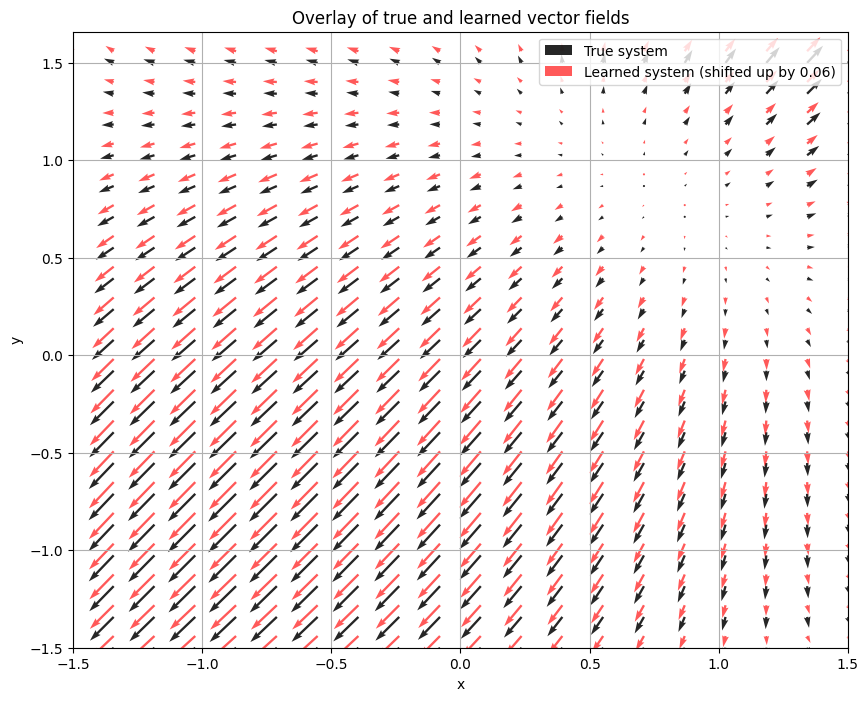

In [11]:
plot_vector_field_overlay(true_func, node.func)

In [26]:
def plot_phase_with_equilibria(true_Z, pred_Z, equilibria, n_samples=30):
    plt.figure(figsize=(8, 8))

    n = min(n_samples, true_Z.size(0))
    for i in range(n):
        true_np = true_Z[i].detach().cpu().numpy()
        pred_np = pred_Z[i].detach().cpu().numpy()

        plt.plot(true_np[:, 0], true_np[:, 1], alpha=0.5)
        plt.plot(pred_np[:, 0], pred_np[:, 1], "--", alpha=0.5)

    if len(equilibria) > 0:
        eq = np.array([p.detach().cpu().numpy() for p in equilibria])
        plt.scatter(eq[:, 0], eq[:, 1], s=100, marker="x", label="Learned equilibria")

    plt.xlabel("x")
    plt.ylabel("y")
    plt.title("Phase portrait with equilibria")
    plt.grid(True)
    plt.legend()
    plt.show()

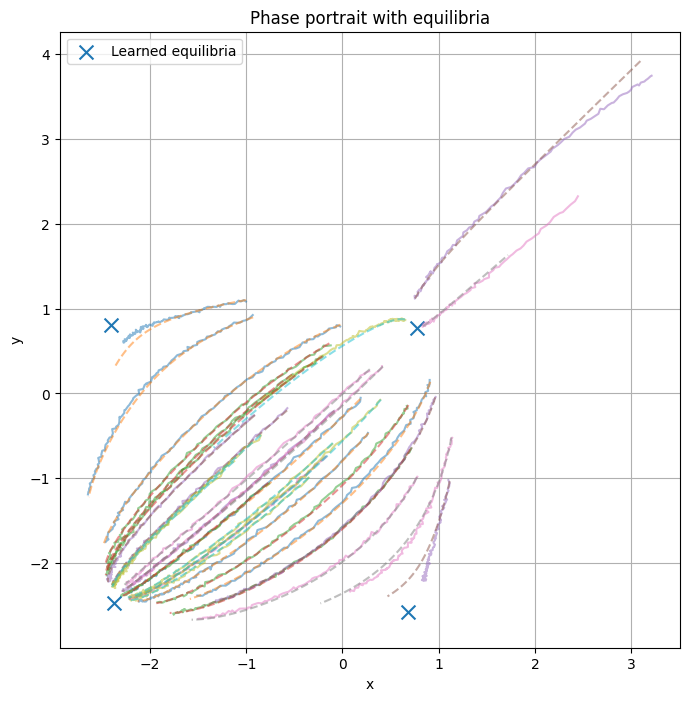

In [27]:
plot_phase_with_equilibria(Z_all, Z_pred_all, equilibria, n_samples=30)

In [28]:
def plot_random_examples(z0_all, Z_all, model, t_eval, n_examples=6):
    idxs = torch.randperm(z0_all.size(0))[:n_examples]

    for idx in idxs:
        z0 = z0_all[idx:idx+1]
        true_traj = Z_all[idx].detach().cpu().numpy()
        pred_traj = model(z0, t_eval)[0].detach().cpu().numpy()

        plt.figure(figsize=(6, 6))
        plt.plot(true_traj[:, 0], true_traj[:, 1], label="true")
        plt.plot(pred_traj[:, 0], pred_traj[:, 1], "--", label="pred")
        plt.scatter(true_traj[0, 0], true_traj[0, 1], c="red", label="start")
        plt.xlabel("x")
        plt.ylabel("y")
        plt.title(f"Trajectory comparison, z0={z0[0].detach().cpu().numpy()}")
        plt.grid(True)
        plt.legend()
        plt.show()

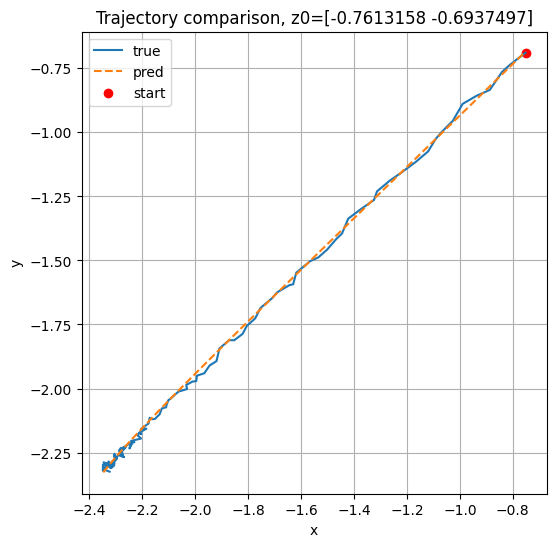

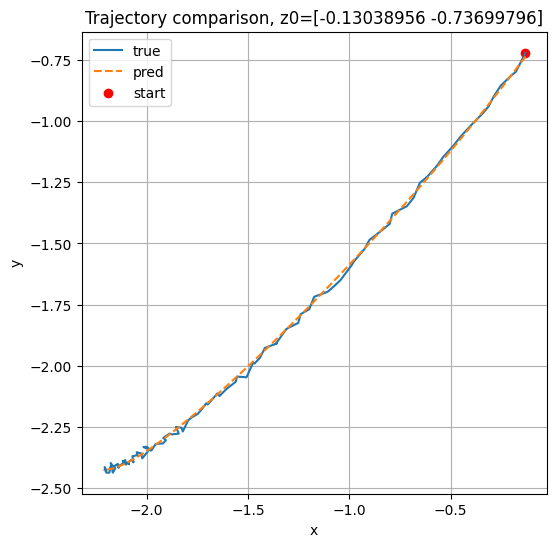

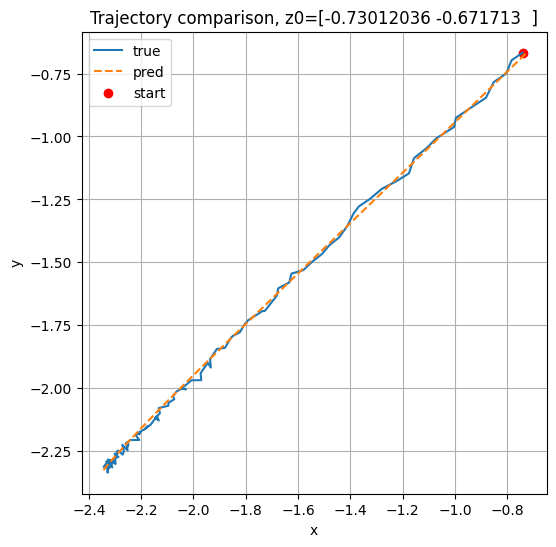

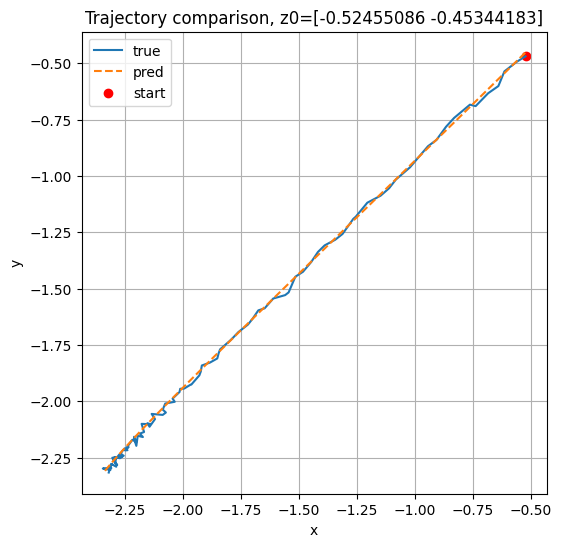

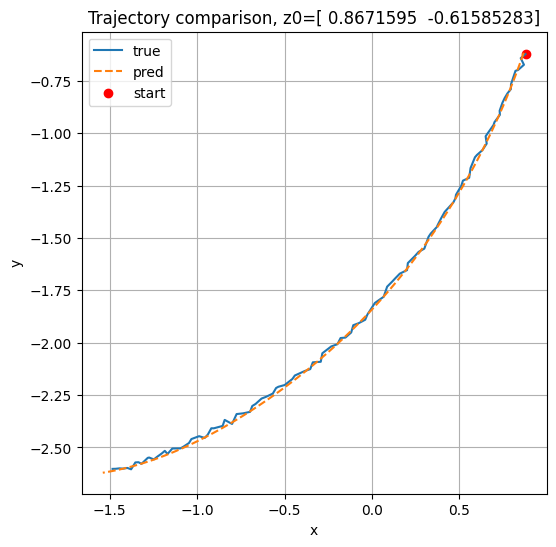

In [29]:
plot_random_examples(z0_all, Z_all, node, t_eval, n_examples=5)